In [1]:
%pip install -q --break-system-packages -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib
import json
import os
import time

os.environ["HF_HOME"] = "models/hf"  # must be set before sentence_transformers is imported

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sentence_transformers import SentenceTransformer
from tqdm import tqdm

CONDITION = "bge_base"
MODEL_NAME = "BAAI/bge-small-en-v1.5"
QUERY_PREFIX = "Represent this sentence for searching relevant passages: "
MAX_LENGTH = 64
SEED = 0
ENTRY_CACHE = f"models/cache/{CONDITION}_entries.npz"  # entry vectors, so a restart skips encoding


def seeded_hash(key):
    return int(hashlib.md5(f"{SEED}:{key}".encode()).hexdigest()[:15], 16)


BLUE = "#2a78d6"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#898781",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.labelcolor": "#52514e",
    "axes.titlelocation": "left", "axes.titlesize": 11,
})
for folder in ["results/rankings", "results/speed", "models/cache"]:
    os.makedirs(folder, exist_ok=True)

/Users/adiram/.local/share/uv/python/cpython-3.11.15-macos-aarch64-none/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1124 13:14:50.075000 73669 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [3]:
data = pd.read_parquet("data/data.parquet")
splits = pd.read_parquet("data/splits.parquet")
histories = pd.read_parquet("data/histories.parquet")

entry_text = dict(zip(data["answer_did"], data["title"] + " | " + data["url"]))

evals = (splits[splits["split"] != "train"]
         .merge(data[["qid", "query", "answer_did", "train_question", "test_question"]], on="qid")
         .merge(histories, on="qid"))
test = evals[evals["split"] == "test"]
questions = pd.concat([
    evals.assign(source="llama", question=evals["test_question"]),
    test.assign(source="qwen", question=test["train_question"]),
    test.assign(source="keyword", question=test["query"]),
], ignore_index=True)

assert questions["question"].notna().all()
assert all(len(h) == 200 for h in questions["history_dids"])
print(questions.groupby(["split", "source"]).size())

split       source 
test        keyword    2000
            llama      2000
            qwen       2000
validation  llama       500
dtype: int64


In [4]:
device = "mps" if torch.backends.mps.is_available() else "cpu"
model = SentenceTransformer(MODEL_NAME, device=device)
model.max_seq_length = MAX_LENGTH
print(f"{MODEL_NAME} on {device}, max length {model.max_seq_length}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 11356.01it/s]


BAAI/bge-small-en-v1.5 on mps, max length 64


230,804 distinct entries across 2,500 histories


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (71 > 64). Running this sequence through the model will result in indexing errors


entries over 64 tokens:   0.74%
questions over 64 tokens: 0.00%


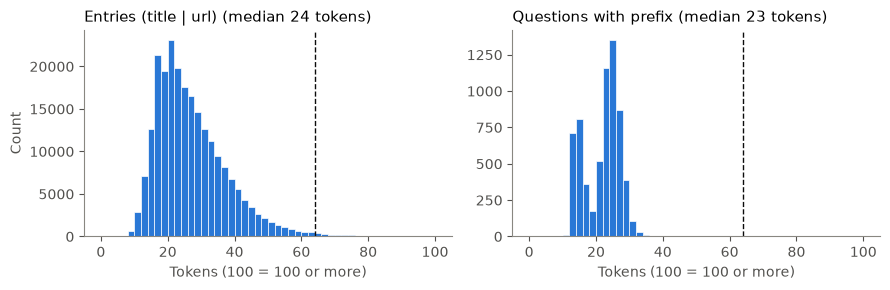

In [5]:
history_dids = sorted(set(did for h in histories["history_dids"] for did in h))
print(f"{len(history_dids):,} distinct entries across {len(histories):,} histories")

# How often the 64-token limit cuts text off, for entries and for prefixed questions.
entry_tokens = pd.Series([len(t) for t in model.tokenizer([entry_text[d] for d in history_dids])["input_ids"]])
question_tokens = pd.Series([len(t) for t in model.tokenizer([QUERY_PREFIX + q for q in questions["question"]])["input_ids"]])
print(f"entries over {MAX_LENGTH} tokens:   {(entry_tokens > MAX_LENGTH).mean():.2%}")
print(f"questions over {MAX_LENGTH} tokens: {(question_tokens > MAX_LENGTH).mean():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, tokens, name in [(axes[0], entry_tokens, "Entries (title | url)"), (axes[1], question_tokens, "Questions with prefix")]:
    ax.hist(tokens.clip(upper=100), bins=range(0, 102, 2), color=BLUE, edgecolor="white", linewidth=0.5)
    ax.axvline(MAX_LENGTH, color="#0b0b0b", linestyle="--", linewidth=1)
    ax.set(title=f"{name} (median {tokens.median():.0f} tokens)", xlabel="Tokens (100 = 100 or more)")
axes[0].set_ylabel("Count")
plt.tight_layout()
plt.savefig(f"results/{CONDITION}_token_lengths.png", dpi=200, bbox_inches="tight")
plt.show()

In [6]:
# Every history entry is encoded once; the vectors are cached so a restart skips this step.
if os.path.exists(ENTRY_CACHE) and list(np.load(ENTRY_CACHE)["dids"]) == history_dids:
    entry_vecs = np.load(ENTRY_CACHE)["vecs"]
    print("loaded cached entry vectors")
else:
    entry_vecs = model.encode([entry_text[d] for d in history_dids], batch_size=256,
                              normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=True)
    np.savez(ENTRY_CACHE, dids=np.array(history_dids), vecs=entry_vecs)

entry_index = {did: i for i, did in enumerate(history_dids)}
did_hash = {did: seeded_hash(did) for did in history_dids}
print(entry_vecs.shape)

Batches: 100%|██████████| 902/902 [01:22<00:00, 10.94it/s]


(230804, 384)


In [7]:
question_vecs = model.encode([QUERY_PREFIX + q for q in questions["question"]], batch_size=256,
                             normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=True)


def rank_history(question_vec, dids):
    # All entries best first; equal scores are ordered by the seeded hash of the page id.
    scores = entry_vecs[[entry_index[d] for d in dids]] @ question_vec
    order = np.lexsort(([did_hash[d] for d in dids], -scores))
    return [dids[i] for i in order]


ranked = [rank_history(vec, list(dids)) for vec, dids in tqdm(zip(question_vecs, questions["history_dids"]), total=len(questions))]
rankings = questions[["qid", "split", "source"]].assign(ranked_dids=ranked)
rankings.to_parquet(f"results/rankings/{CONDITION}.parquet", index=False)
print(f"saved {len(rankings):,} rankings")

100%|██████████| 6500/6500 [00:00<00:00, 8434.06it/s]


saved 6,500 rankings


In [8]:
# CPU speed: a second copy of the model on the CPU, timed on 2,000 entries and 500 test questions.
cpu_model = SentenceTransformer(MODEL_NAME, device="cpu")
cpu_model.max_seq_length = MAX_LENGTH
print(f"CPU threads: {torch.get_num_threads()}")

speed_entries = pd.Series(history_dids).sample(2_000, random_state=SEED).map(entry_text).tolist()
speed_questions = questions[(questions["split"] == "test") & (questions["source"] == "llama")].sample(500, random_state=SEED)

cpu_model.encode(speed_entries[:64], batch_size=64, normalize_embeddings=True)  # warm-up
start = time.perf_counter()
cpu_model.encode(speed_entries, batch_size=64, normalize_embeddings=True)
entry_ms = (time.perf_counter() - start) * 1000 / len(speed_entries)

question_times = []
for question, dids in tqdm(zip(speed_questions["question"], speed_questions["history_dids"]), total=len(speed_questions)):
    vecs = entry_vecs[[entry_index[d] for d in dids]]  # entry vectors are precomputed, as in the application
    start = time.perf_counter()
    vec = cpu_model.encode(QUERY_PREFIX + question, normalize_embeddings=True)
    order = np.argsort(-(vecs @ vec))
    question_times.append((time.perf_counter() - start) * 1000)
question_ms = float(np.mean(question_times))

speed = {"entry_ms": round(entry_ms, 3), "question_ms": round(question_ms, 3)}
with open(f"results/speed/{CONDITION}.json", "w") as f:
    json.dump(speed, f)
print(speed, f"(question median {np.median(question_times):.2f} ms)")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 28269.82it/s]


CPU threads: 6


100%|██████████| 500/500 [00:02<00:00, 167.64it/s]

{'entry_ms': 1.824, 'question_ms': 5.813} (question median 5.71 ms)


In [9]:
# Sanity check on validation: where the answer lands for the Llama questions.
validation = rankings[(rankings["split"] == "validation") & (rankings["source"] == "llama")].merge(questions[["qid", "source", "question", "answer_did"]], on=["qid", "source"])
validation["rank"] = [list(r).index(a) + 1 for r, a in zip(validation["ranked_dids"], validation["answer_did"])]
print(f"validation llama questions: {len(validation)}")
print(f"validation Recall@1 {(validation['rank'] <= 1).mean():.1%}   Recall@5 {(validation['rank'] <= 5).mean():.1%}   median rank {validation['rank'].median():.0f}")

for row in validation.sample(5, random_state=SEED).itertuples():
    print(f"\nQ: {row.question}")
    print(f"   answer (rank {row.rank}): {entry_text[row.answer_did]}")
    for i, did in enumerate(row.ranked_dids[:3]):
        print(f"   {i + 1}. {entry_text[did]}")

validation llama questions: 500
validation Recall@1 65.4%   Recall@5 89.6%   median rank 1

Q: What does the Wikipedia article about the right to assemble say about that?
   answer (rank 1): Freedom of assembly | en.wikipedia.org/wiki/Freedom_of_assembly
   1. Freedom of assembly | en.wikipedia.org/wiki/Freedom_of_assembly
   2. Vehicle Assembly Building | en.wikipedia.org/wiki/Vehicle_Assembly_Building
   3. assembly | thefreedictionary.com/assembly

Q: What's the layout of that Mystic Seaport I was looking at?
   answer (rank 1): Mystic Seaport | mapquest.com/us/ct/mystic-seaport-283398121
   1. Mystic Seaport | mapquest.com/us/ct/mystic-seaport-283398121
   2. Mystic Seaport | tripadvisor.com/Attraction_Review-g33845-d104984-Reviews-Mystic_Seaport-Mystic_Connecticut.html
   3. Into the Mystic | en.wikipedia.org/wiki/Into_the_Mystic

Q: What's the name of that horse breed I read about on Wikipedia?
   answer (rank 34): Lipizzan | en.wikipedia.org/wiki/Lipizzan
   1. Red Dog (Pilbara)